# Book Recommender Using a Medallion Data Lake
# Lab Assignment - 2

**Name:** Sumit Kumar  
**Roll Number:** LCS2023044  
**Course:** Data Mining


## Objective

Build an item-based book recommender using the Book-Crossing dataset through a simulated Bronze–Silver–Gold data lake.

## Pipeline

Raw CSV files → Bronze → Exploratory Data Analysis → Silver → Gold → Item-Based Collaborative Filtering → Recommendations

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors
from collections import defaultdict

import warnings
warnings.filterwarnings('ignore')

for folder in ['bronze', 'silver', 'gold']:
    os.makedirs(folder, exist_ok=True)

print("Data lake folders created successfully")

Data lake folders created successfully


In [3]:
books = pd.read_csv(
    '/content/BX-Books.csv',
    sep=';',
    encoding='latin-1',
    escapechar='\\',
    dtype=str
)

users = pd.read_csv(
    '/content/BX-Users.csv',
    sep=';',
    encoding='latin-1',
    dtype=str
)

ratings = pd.read_csv(
    '/content/BX-Book-Ratings.csv',
    sep=';',
    encoding='latin-1',
    dtype=str
)

print("Books:", books.shape)
print("Users:", users.shape)
print("Ratings:", ratings.shape)

Books: (271379, 8)
Users: (278858, 3)
Ratings: (1149780, 3)


In [4]:
timestamp = pd.Timestamp.now(tz='UTC')

books['ingestion_timestamp'] = timestamp
users['ingestion_timestamp'] = timestamp
ratings['ingestion_timestamp'] = timestamp

books.to_parquet('bronze/books.parquet', index=False)
users.to_parquet('bronze/users.parquet', index=False)
ratings.to_parquet('bronze/ratings.parquet', index=False)

print("Bronze layer created successfully")

Bronze layer created successfully


# Exploratory Data Analysis (EDA)

In [5]:
books = pd.read_parquet('bronze/books.parquet')
users = pd.read_parquet('bronze/users.parquet')
ratings = pd.read_parquet('bronze/ratings.parquet')

for name, df in [('Books', books),
                 ('Users', users),
                 ('Ratings', ratings)]:
    print("\n", "=" * 40)
    print(name)
    print("Shape:", df.shape)
    print("\nData Types:")
    print(df.dtypes)
    print("\nMissing Values:")
    print(df.isnull().sum())
    print("\nDuplicate Rows:", df.duplicated().sum())
    display(df.head())


Books
Shape: (271379, 9)

Data Types:
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                 object
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0
dtype: int64

Duplicate Rows: 0


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,2026-11-26 12:29:51.652193+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,2026-11-26 12:29:51.652193+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,2026-11-26 12:29:51.652193+00:00
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,2026-11-26 12:29:51.652193+00:00
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,2026-11-26 12:29:51.652193+00:00



Users
Shape: (278858, 4)

Data Types:
User-ID                             object
Location                            object
Age                                 object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

Duplicate Rows: 0


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",None,2026-11-26 12:29:51.652193+00:00
1,2,"stockton, california, usa",18,2026-11-26 12:29:51.652193+00:00
2,3,"moscow, yukon territory, russia",None,2026-11-26 12:29:51.652193+00:00
3,4,"porto, v.n.gaia, portugal",17,2026-11-26 12:29:51.652193+00:00
4,5,"farnborough, hants, united kingdom",None,2026-11-26 12:29:51.652193+00:00



Ratings
Shape: (1149780, 4)

Data Types:
User-ID                             object
ISBN                                object
Book-Rating                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                0
ISBN                   0
Book-Rating            0
ingestion_timestamp    0
dtype: int64

Duplicate Rows: 0


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-26 12:29:51.652193+00:00
1,276726,0155061224,5,2026-11-26 12:29:51.652193+00:00
2,276727,0446520802,0,2026-11-26 12:29:51.652193+00:00
3,276729,052165615X,3,2026-11-26 12:29:51.652193+00:00
4,276729,0521795028,6,2026-11-26 12:29:51.652193+00:00


Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64
Zero ratings: 716109
Explicit ratings: 433671


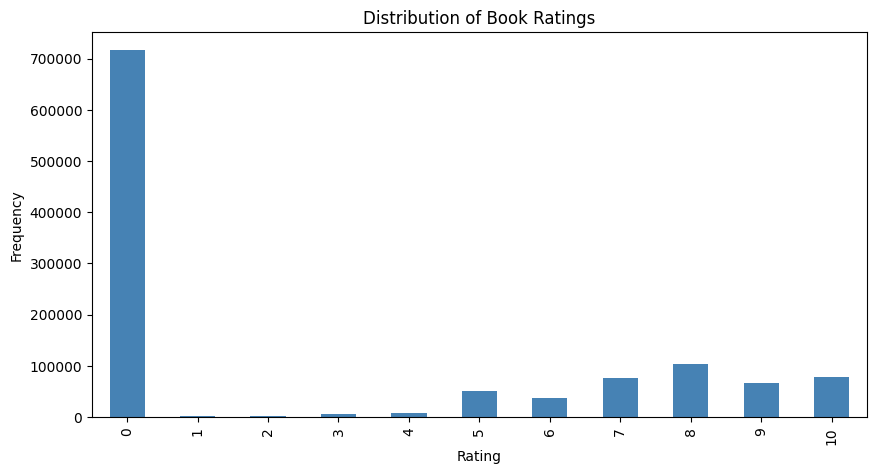

In [6]:
rating_values = pd.to_numeric(
    ratings['Book-Rating'], errors='coerce'
)

print(rating_values.value_counts().sort_index())
print("Zero ratings:", (rating_values == 0).sum())
print("Explicit ratings:", (rating_values > 0).sum())

rating_values.value_counts().sort_index().plot(
    kind='bar', figsize=(10, 5), color='steelblue'
)

plt.title('Distribution of Book Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Missing ages: 110762
Invalid ages: 1248


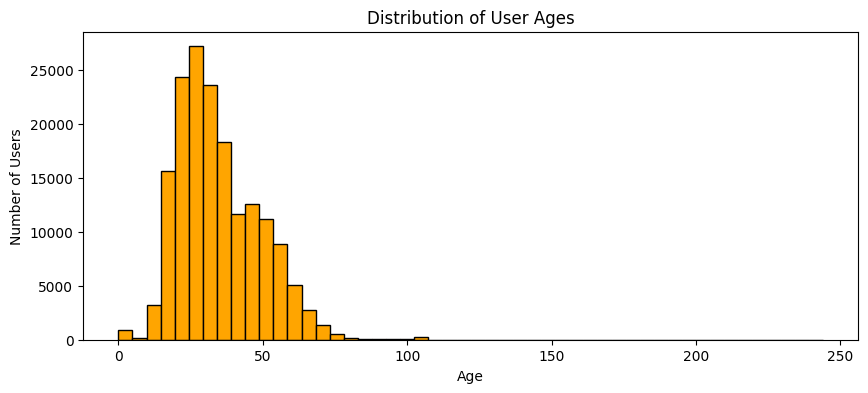

In [7]:
ages = pd.to_numeric(users['Age'], errors='coerce')

print(ages.describe())
print("Missing ages:", ages.isnull().sum())
print("Invalid ages:", ((ages < 5) | (ages > 100)).sum())

plt.figure(figsize=(10, 4))
plt.hist(ages.dropna(), bins=50, color='orange', edgecolor='black')
plt.title('Distribution of User Ages')
plt.xlabel('Age')
plt.ylabel('Number of Users')
plt.show()

Ratings per user:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64


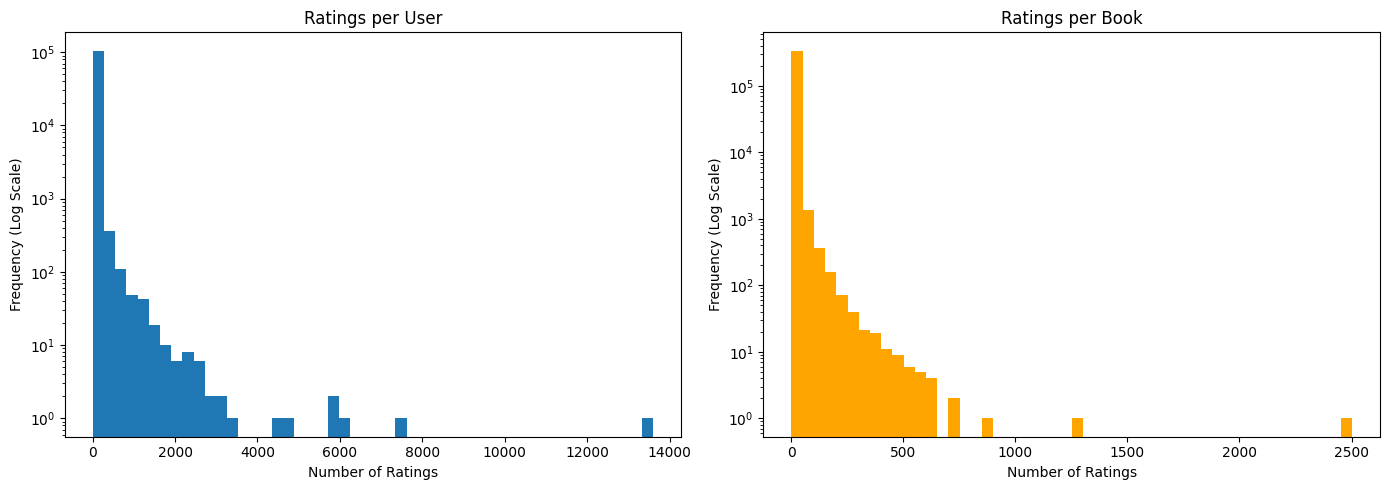

In [8]:
ratings_per_user = ratings.groupby('User-ID').size()
ratings_per_book = ratings.groupby('ISBN').size()

print("Ratings per user:")
print(ratings_per_user.describe())

print("\nRatings per book:")
print(ratings_per_book.describe())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].hist(ratings_per_user, bins=50, log=True)
ax[0].set_title('Ratings per User')
ax[0].set_xlabel('Number of Ratings')
ax[0].set_ylabel('Frequency (Log Scale)')

ax[1].hist(ratings_per_book, bins=50, log=True, color='orange')
ax[1].set_title('Ratings per Book')
ax[1].set_xlabel('Number of Ratings')
ax[1].set_ylabel('Frequency (Log Scale)')

plt.tight_layout()
plt.show()

In [9]:
total_users = users['User-ID'].nunique()
total_books = books['ISBN'].nunique()

valid_pairs = ratings[
    ratings['User-ID'].isin(users['User-ID']) &
    ratings['ISBN'].isin(books['ISBN'])
]

actual_ratings = valid_pairs[
    ['User-ID', 'ISBN']
].drop_duplicates().shape[0]

possible_ratings = total_users * total_books

density = actual_ratings / possible_ratings * 100
sparsity = 100 - density

print("Total Users:", total_users)
print("Total Books:", total_books)
print("Possible Ratings:", possible_ratings)
print("Observed Pairs:", actual_ratings)
print(f"Matrix Density: {density:.6f}%")
print(f"Matrix Sparsity: {sparsity:.6f}%")

Total Users: 278858
Total Books: 271379
Possible Ratings: 75676205182
Observed Pairs: 1031175
Matrix Density: 0.001363%
Matrix Sparsity: 99.998637%


# Matrix sparsity

In [10]:
total_users = users['User-ID'].nunique()
total_books = books['ISBN'].nunique()

valid_pairs = ratings[
    ratings['User-ID'].isin(users['User-ID']) &
    ratings['ISBN'].isin(books['ISBN'])
]

actual_ratings = valid_pairs[
    ['User-ID', 'ISBN']
].drop_duplicates().shape[0]

possible_ratings = total_users * total_books

density = actual_ratings / possible_ratings * 100
sparsity = 100 - density

print("Total Users:", total_users)
print("Total Books:", total_books)
print("Possible Ratings:", possible_ratings)
print("Observed Pairs:", actual_ratings)
print(f"Matrix Density: {density:.6f}%")
print(f"Matrix Sparsity: {sparsity:.6f}%")

Total Users: 278858
Total Books: 271379
Possible Ratings: 75676205182
Observed Pairs: 1031175
Matrix Density: 0.001363%
Matrix Sparsity: 99.998637%


## EDA Observations

- The dataset contains 271,379 books, 278,858 users and 1,149,780 rating records. Raw fields are loaded as strings; Silver will convert numeric fields and preserve ISBNs as strings. No exact duplicate rows were found. Books have two missing authors and two missing publishers.
- There are 716,109 zero ratings representing implicit interactions. These will be removed from the explicit training data.
- The Users table contains 110,762 missing ages and 1,248 invalid ages. Invalid ages will be replaced with null and missing ages will be filled using the median age of 32.
- Publication years range from 0 to 2050, including 4,619 zero years and 11 years beyond 2026. Zero and future years will be replaced with null.
- The median number of ratings per active user and per rated book is 1. A minimum threshold of 10 ratings per user and book will remove poorly supported entities and improve similarity reliability.
- Approximately 0.001363% of possible user-book pairs have an observed rating record, resulting in 99.998637% sparsity. A sparse matrix will be used to store the Gold data efficiently.

## Cleaning the data and building the Silver layer

In [11]:
books = pd.read_parquet('bronze/books.parquet')
users = pd.read_parquet('bronze/users.parquet')
ratings = pd.read_parquet('bronze/ratings.parquet')

books = books.drop_duplicates().copy()
users = users.drop_duplicates().copy()
ratings = ratings.drop_duplicates().copy()

users['User-ID'] = pd.to_numeric(
    users['User-ID'], errors='coerce'
)

ratings['User-ID'] = pd.to_numeric(
    ratings['User-ID'], errors='coerce'
)

ratings['Book-Rating'] = pd.to_numeric(
    ratings['Book-Rating'], errors='coerce'
)

users['Age'] = pd.to_numeric(
    users['Age'], errors='coerce'
)

books['Year-Of-Publication'] = pd.to_numeric(
    books['Year-Of-Publication'], errors='coerce'
)

print("Duplicates removed and data types corrected")

Duplicates removed and data types corrected


In [12]:
ratings = ratings[
    ratings['Book-Rating'].between(1, 10)
].copy()

print("Remaining explicit ratings:", len(ratings))

Remaining explicit ratings: 433671


In [13]:
users.loc[
    (users['Age'] < 5) | (users['Age'] > 100),
    'Age'
] = np.nan

median_age = users['Age'].median()

users['Age'] = users['Age'].fillna(median_age)
users['Age'] = users['Age'].astype(int)

print("Median Age:", median_age)
print("Missing Ages:", users['Age'].isnull().sum())

Median Age: 32.0
Missing Ages: 0


Split Location into City, State and Country

In [14]:
location = users['Location'].str.rsplit(
    ',', n=2, expand=True
)

users['City'] = location[0]
users['State'] = location[1]
users['Country'] = location[2]

for col in ['City', 'State', 'Country']:
    users[col] = users[col].str.strip().str.lower()
    users[col] = users[col].replace('', np.nan)

users = users.drop(columns=['Location'])

display(users.head())

,User-ID,Age,ingestion_timestamp,City,State,Country
0,1,32,2026-11-26 12:29:51.652193+00:00,nyc,new york,usa
1,2,18,2026-11-26 12:29:51.652193+00:00,stockton,california,usa
2,3,32,2026-11-26 12:29:51.652193+00:00,moscow,yukon territory,russia
3,4,17,2026-11-26 12:29:51.652193+00:00,porto,v.n.gaia,portugal
4,5,32,2026-11-26 12:29:51.652193+00:00,farnborough,hants,united kingdom


In [15]:
# Fix invalid publication years
current_year = pd.Timestamp.now(tz='UTC').year
books.loc[(books['Year-Of-Publication'] <= 0) | (books['Year-Of-Publication'] > current_year), 'Year-Of-Publication'] = np.nan
books['Year-Of-Publication'] = books['Year-Of-Publication'].astype('Int64')
print('Missing publication years:', books['Year-Of-Publication'].isna().sum())


Missing publication years: 4630


In [16]:
# Standardise book text and identifiers; remove unused image URLs
for col in ['Book-Title', 'Book-Author', 'Publisher']:
    books[col] = books[col].str.strip().str.replace(r'\s+', ' ', regex=True).str.title()
books['ISBN'] = books['ISBN'].str.strip().str.upper()
ratings['ISBN'] = ratings['ISBN'].str.strip().str.upper()
books = books.drop(columns=['Image-URL-S', 'Image-URL-M', 'Image-URL-L'])
books = books.drop_duplicates(subset=['ISBN'])
users = users.dropna(subset=['User-ID']).drop_duplicates(subset=['User-ID'])
users['User-ID'] = users['User-ID'].astype('int64')
ratings = ratings.drop_duplicates()

# Enforce referential integrity and one rating per user-book pair
ratings = ratings[ratings['User-ID'].isin(users['User-ID']) & ratings['ISBN'].isin(books['ISBN'])].copy()
ratings['User-ID'] = ratings['User-ID'].astype('int64')
ratings = ratings.groupby(['User-ID', 'ISBN'], as_index=False)['Book-Rating'].mean()
print('Valid explicit ratings before frequency filtering:', len(ratings))
display(books.head())


Valid explicit ratings before frequency filtering: 383853


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,2026-11-26 12:29:51.652193+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada,2026-11-26 12:29:51.652193+00:00
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial,2026-11-26 12:29:51.652193+00:00
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,2026-11-26 12:29:51.652193+00:00
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton &Amp; Company,2026-11-26 12:29:51.652193+00:00


In [17]:
# Iteratively retain users and books with at least 10 explicit ratings
min_ratings = 10
filter_rounds = 0
while True:
    old_size = len(ratings)
    user_counts = ratings['User-ID'].value_counts()
    ratings = ratings[ratings['User-ID'].map(user_counts) >= min_ratings]
    book_counts = ratings['ISBN'].value_counts()
    ratings = ratings[ratings['ISBN'].map(book_counts) >= min_ratings]
    filter_rounds += 1
    if len(ratings) == old_size:
        break
ratings = ratings.copy()
users = users[users['User-ID'].isin(ratings['User-ID'])].copy()
books = books[books['ISBN'].isin(ratings['ISBN'])].copy()
assert not ratings.empty
assert ratings.groupby('User-ID').size().min() >= min_ratings
assert ratings.groupby('ISBN').size().min() >= min_ratings
assert not ratings.duplicated(['User-ID', 'ISBN']).any()
for name, df in [('books', books), ('users', users), ('ratings', ratings)]:
    df.to_parquet(f'silver/{name}.parquet', index=False)
print('Filter rounds:', filter_rounds)
print('Final Users:', len(users), '| Final Books:', len(books), '| Final Ratings:', len(ratings))
print('Silver layer saved successfully')


Filter rounds: 7
Final Users: 1820 | Final Books: 2030 | Final Ratings: 41469
Silver layer saved successfully


## Threshold selection

A minimum of 10 explicit ratings per user and book was chosen because the median interaction count is only one. Iterative filtering improves support for cosine similarity and reduces computation, while sacrificing coverage of less active users and less popular books. Filtering continues until both thresholds hold. The resulting Silver layer contains 1,820 users, 2,030 books and 41,469 ratings.

## Gold layer

The following cells create a sparse user-by-book matrix, persistent index mappings, a book lookup and user/book aggregates. Only observed explicit ratings are stored.


In [20]:
# Load cleaned Silver data and create a sparse user-book rating matrix.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors
from IPython.display import display, Markdown

Path("gold").mkdir(exist_ok=True)

books = pd.read_parquet("silver/books.parquet")
users = pd.read_parquet("silver/users.parquet")
ratings = pd.read_parquet("silver/ratings.parquet")

user_ids = sorted(ratings["User-ID"].unique().tolist())
book_ids = sorted(ratings["ISBN"].unique().tolist())

user_map = {uid: i for i, uid in enumerate(user_ids)}
book_map = {isbn: i for i, isbn in enumerate(book_ids)}

rating_matrix = csr_matrix(
    (
        ratings["Book-Rating"].to_numpy(dtype=np.float32),
        (
            ratings["User-ID"].map(user_map).to_numpy(),
            ratings["ISBN"].map(book_map).to_numpy()
        )
    ),
    shape=(len(user_ids), len(book_ids))
)

gold_sparsity = 100 * (
    1 - rating_matrix.nnz /
    (rating_matrix.shape[0] * rating_matrix.shape[1])
)

print("Matrix shape:", rating_matrix.shape)
print("Non-zero ratings:", rating_matrix.nnz)
print(f"Gold matrix sparsity: {gold_sparsity:.2f}%")

Matrix shape: (1820, 2030)
Non-zero ratings: 41469
Gold matrix sparsity: 98.88%


In [21]:
# Create book metadata lookup and user-level/book-level statistics.
book_lookup = (
    books.set_index("ISBN")
    .loc[book_ids, ["Book-Title", "Book-Author"]]
    .reset_index()
)

user_aggregates = ratings.groupby("User-ID").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

book_aggregates = ratings.groupby("ISBN").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

print("Book lookup:")
display(book_lookup.head())

print("User aggregates:")
display(user_aggregates.head())

print("Book aggregates:")
display(book_aggregates.head())

Book lookup:


,ISBN,Book-Title,Book-Author
0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald
1,0020442203,"Lion, The Witch And The Wardrobe",C.S. Lewis
2,002542730X,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner
3,0028604199,Once Upon A More Enlightened Time: More Politi...,James Finn Garner
4,0060002050,On A Wicked Dawn (Cynster Novels),Stephanie Laurens


User aggregates:


,User-ID,average_rating,number_of_ratings
0,243,7.769231,13
1,254,8.450000,20
2,638,9.454545,22
3,805,8.400000,10
4,882,8.235294,17


Book aggregates:


,ISBN,average_rating,number_of_ratings
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11


In [22]:
# Save the sparse matrix, lookup, aggregates and index mappings to Gold.
save_npz("gold/rating_matrix.npz", rating_matrix)

book_lookup.to_parquet("gold/book_lookup.parquet", index=False)
user_aggregates.to_parquet("gold/user_aggregates.parquet", index=False)
book_aggregates.to_parquet("gold/book_aggregates.parquet", index=False)

pd.DataFrame({"User-ID": user_ids}).to_parquet(
    "gold/user_ids.parquet", index=False
)

pd.DataFrame({"ISBN": book_ids}).to_parquet(
    "gold/book_ids.parquet", index=False
)

print("Gold layer saved successfully")

Gold layer saved successfully


In [23]:
# Reload Gold artifacts and fit an item-based cosine-similarity model.
rating_matrix = load_npz("gold/rating_matrix.npz").tocsr()

user_ids = pd.read_parquet(
    "gold/user_ids.parquet"
)["User-ID"].tolist()

book_ids = pd.read_parquet(
    "gold/book_ids.parquet"
)["ISBN"].tolist()

book_lookup = pd.read_parquet("gold/book_lookup.parquet")

user_map = {uid: i for i, uid in enumerate(user_ids)}
book_map = {isbn: i for i, isbn in enumerate(book_ids)}
lookup = book_lookup.set_index("ISBN")

# Transpose so each row represents a book and each column a user.
book_user_matrix = rating_matrix.T.tocsr()

model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

model.fit(book_user_matrix)

# Include one extra neighbor because each book is its own neighbor.
neighbor_count = min(51, len(book_ids))

distances, indices = model.kneighbors(
    book_user_matrix,
    n_neighbors=neighbor_count
)

print("Item-based cosine-similarity model ready")

Item-based cosine-similarity model ready


In [24]:
# Preserve all previous interactions, including zero ratings, for exclusion.
history = pd.read_parquet(
    "bronze/ratings.parquet",
    columns=["User-ID", "ISBN"]
)

history["User-ID"] = pd.to_numeric(
    history["User-ID"], errors="coerce"
)

history["ISBN"] = history["ISBN"].str.strip().str.upper()

history = history[
    history["User-ID"].isin(user_ids)
].drop_duplicates(["User-ID", "ISBN"]).copy()

history["User-ID"] = history["User-ID"].astype("int64")

seen_books = (
    history.groupby("User-ID")["ISBN"]
    .agg(set)
    .to_dict()
)

history.to_parquet("gold/seen_books.parquet", index=False)

print("Interaction histories saved for", len(seen_books), "users")

Interaction histories saved for 1820 users


In [25]:
# Define a function that returns books similar to an ISBN or exact title.
def similar_books(book, n=10):
    columns = ["ISBN", "Book-Title", "Book-Author", "Similarity"]

    if n <= 0:
        return pd.DataFrame(columns=columns)

    query = str(book).strip()
    isbn = query.upper()

    if isbn not in book_map:
        matches = book_lookup[
            book_lookup["Book-Title"].str.casefold() == query.casefold()
        ]

        if matches.empty:
            print("Book not found in Gold:", book)
            return pd.DataFrame(columns=columns)

        # For duplicate titles, use the first matching ISBN.
        isbn = matches.iloc[0]["ISBN"]

    source_idx = book_map[isbn]

    dists, neighbors = model.kneighbors(
        book_user_matrix.getrow(source_idx),
        n_neighbors=min(n + 1, len(book_ids))
    )

    results = []

    for dist, idx in zip(dists[0], neighbors[0]):
        if idx == source_idx:
            continue

        candidate = book_ids[idx]

        results.append({
            "ISBN": candidate,
            "Book-Title": lookup.loc[candidate, "Book-Title"],
            "Book-Author": lookup.loc[candidate, "Book-Author"],
            "Similarity": float(np.clip(1 - dist, 0, 1))
        })

    return pd.DataFrame(results, columns=columns).head(n)


example_isbn = book_ids[0]

print("Similar books to:", lookup.loc[example_isbn, "Book-Title"])
display(similar_books(example_isbn, 10))

Similar books to: Great Gatsby (Reissue)


,ISBN,Book-Title,Book-Author,Similarity
0,0446322180,Name Of The Rose-Nla,Umberto Eco,0.269862
1,055356773X,The Cereal Murders,Diane Mott Davidson,0.197447
2,0345413369,"The Subtle Knife (His Dark Materials, Book 2)",Philip Pullman,0.189793
3,0156528207,The Little Prince,Antoine De Saint-Exupã©Ry,0.149917
4,0440967694,The Outsiders,S. E. Hinton,0.147883
5,0553563521,Devil'S Waltz (Alex Delaware Novels (Paperback)),Jonathan Kellerman,0.136965
6,0060938455,Fast Food Nation: The Dark Side Of The All-Ame...,Eric Schlosser,0.133844
7,0140481389,The Crucible: A Play In Four Acts (Penguin Plays),Arthur Miller,0.133048
8,0688177867,The Book Borrower: A Novel,Alice Mattison,0.131731
9,034543479X,A Widow For One Year,John Irving,0.127810


In [26]:
# Recommend unseen books using similarity-weighted ratings of liked books.
REC_COLUMNS = [
    "ISBN", "Book-Title", "Book-Author", "Recommendation-Score"
]


def recommend(user_id, n=10):
    if user_id not in user_map or n <= 0:
        return pd.DataFrame(columns=REC_COLUMNS)

    user_ratings = rating_matrix.getrow(user_map[user_id])

    excluded = set(seen_books.get(user_id, set()))
    excluded.update(book_ids[i] for i in user_ratings.indices)

    scores = defaultdict(float)

    for source_idx, rating in zip(
        user_ratings.indices, user_ratings.data
    ):
        # A rating of 8 or higher identifies a liked book.
        if rating < 8:
            continue

        for dist, candidate_idx in zip(
            distances[source_idx], indices[source_idx]
        ):
            if candidate_idx == source_idx:
                continue

            isbn = book_ids[candidate_idx]
            similarity = float(np.clip(1 - dist, 0, 1))

            if isbn not in excluded and similarity > 0:
                scores[isbn] += similarity * float(rating)

    ranked = sorted(
        scores.items(),
        key=lambda item: (-item[1], item[0])
    )[:n]

    return pd.DataFrame([
        {
            "ISBN": isbn,
            "Book-Title": lookup.loc[isbn, "Book-Title"],
            "Book-Author": lookup.loc[isbn, "Book-Author"],
            "Recommendation-Score": score
        }
        for isbn, score in ranked
    ], columns=REC_COLUMNS)


print("Recommendation function ready")

Recommendation function ready


In [27]:
# Retrieve books a user rated at least 8 for comparison with recommendations.
def get_liked_books(user_id):
    columns = ["ISBN", "Book-Title", "Book-Author", "Rating"]

    if user_id not in user_map:
        return pd.DataFrame(columns=columns)

    user_ratings = rating_matrix.getrow(user_map[user_id])
    result = []

    for idx, rating in zip(
        user_ratings.indices, user_ratings.data
    ):
        if rating >= 8:
            isbn = book_ids[idx]

            result.append({
                "ISBN": isbn,
                "Book-Title": lookup.loc[isbn, "Book-Title"],
                "Book-Author": lookup.loc[isbn, "Book-Author"],
                "Rating": float(rating)
            })

    return pd.DataFrame(result, columns=columns).sort_values(
        "Rating", ascending=False
    ).reset_index(drop=True)


print("Liked-books function ready")

Liked-books function ready


In [28]:
# Display liked books and top 10 recommendations for three sample users.
sample_users = [243, 805, 1424]
demo_results = {}

for uid in sample_users:
    print("\n" + "=" * 70)
    print("USER ID:", uid)
    print("=" * 70)

    print("\nHighly rated books:")
    display(get_liked_books(uid))

    recs = recommend(uid, 10)
    demo_results[uid] = recs

    print("\nTop 10 recommendations:")
    display(recs)

    recs.to_csv(
        f"gold/recommendations_user_{uid}.csv",
        index=False
    )


USER ID: 243

Highly rated books:


,ISBN,Book-Title,Book-Author,Rating
0,0060915544,The Bean Trees,Barbara Kingsolver,10.0
1,0375400117,Memoirs Of A Geisha,Arthur Golden,10.0
2,0316601950,The Pilot'S Wife : A Novel,Anita Shreve,9.0
3,0316776963,Me Talk Pretty One Day,David Sedaris,9.0
4,0425163407,Unnatural Exposure,Patricia Daniels Cornwell,9.0
5,0446364800,The General'S Daughter,Nelson Demille,9.0



Top 10 recommendations:


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,0385265700,The Book Of Ruth (Oprah'S Book Club (Paperback)),Jane Hamilton,3.847579
1,0425147622,The Body Farm,Patricia Daniels Cornwell,3.575107
2,0425154092,From Potter'S Field,Patricia Daniels Cornwell,3.338379
3,0060921145,Animal Dreams,Barbara Kingsolver,3.230984
4,0425169863,Point Of Origin,Patricia Daniels Cornwell,3.024232
5,1400031354,Tears Of The Giraffe (No.1 Ladies Detective Ag...,Alexander Mccall Smith,2.957377
6,0060922532,Pigs In Heaven,Barbara Kingsolver,2.923849
7,0425137562,Silent Prey,John Sandford,2.896350
8,0385729332,The Sisterhood Of The Traveling Pants,Ann Brashares,2.875071
9,0380726254,Serpent'S Tooth : A Peter Decker/Rina Lazarus ...,Faye Kellerman,2.776450



USER ID: 805

Highly rated books:


,ISBN,Book-Title,Book-Author,Rating
0,0060256672,Where The Sidewalk Ends : Poems And Drawings,Shel Silverstein,10.0
1,0877733759,Writing Down The Bones,Natalie Goldberg,10.0
2,039592720X,Interpreter Of Maladies,Jhumpa Lahiri,9.0
3,0156027321,Life Of Pi,Yann Martel,9.0
4,0440215625,Dragonfly In Amber,Diana Gabaldon,8.0
5,0452282152,Girl With A Pearl Earring,Tracy Chevalier,8.0
6,0553268449,Jitterbug Perfume,Tom Robbins,8.0
7,0671003755,She'S Come Undone (Oprah'S Book Club (Paperback)),Wally Lamb,8.0


... (2 outputs left out)


USER ID: 1424

Highly rated books:


,ISBN,Book-Title,Book-Author,Rating
0,0061015725,Prey,Michael Crichton,8.0
1,0099771519,Memoirs Of A Geisha Uk,Arthur Golden,8.0
2,0156001314,The Name Of The Rose: Including Postscript To ...,Umberto Eco,8.0
3,0671776134,Plain Truth,Jodi Picoult,8.0
4,0767902521,A Walk In The Woods: Rediscovering America On ...,Bill Bryson,8.0



Top 10 recommendations:


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,0552998001,Blackberry Wine,Joanne Harris,3.656265
1,0140042598,On The Road,Jack Kerouac,3.423364
2,0802132952,Naked Lunch,William S. Burroughs,2.972037
3,0385337639,Crow Lake (Today Show Book Club #7),Mary Lawson,2.681670
4,0393312836,A Clockwork Orange (Norton Paperback Fiction),Anthony Burgess,2.462760
5,0064400042,On The Banks Of Plum Creek,Laura Ingalls Wilder,2.391844
6,0385503954,Atonement: A Novel,Ian Mcewan,2.236114
7,0451523377,Dracula (Signet Classics (Paperback)),Bram Stoker,2.233224
8,0375703861,White Teeth: A Novel,Zadie Smith,2.223803
9,0156711427,A Passage To India,E.M. Forster,2.209937


In [29]:
# Verify matrix integrity, unique recommendations, exclusions and ranking.
assert rating_matrix.shape == (len(user_ids), len(book_ids))
assert rating_matrix.nnz == len(ratings)
assert np.isfinite(rating_matrix.data).all()
assert np.all(
    (rating_matrix.data >= 1) & (rating_matrix.data <= 10)
)

for uid, recs in demo_results.items():
    assert len(recs) == 10, f"User {uid}: fewer than 10 recommendations"
    assert recs["ISBN"].is_unique

    assert set(recs["ISBN"]).isdisjoint(
        seen_books.get(uid, set())
    )

    assert recs["Recommendation-Score"].is_monotonic_decreasing
    assert np.isfinite(recs["Recommendation-Score"]).all()
    assert (recs["Recommendation-Score"] > 0).all()

    print(f"User {uid}: All sanity checks passed")

# Verify unknown-user and empty-request handling.
assert recommend(-1).empty
assert recommend(sample_users[0], 0).empty

print("Matrix and edge-case checks passed")

User 243: All sanity checks passed
User 805: All sanity checks passed
User 1424: All sanity checks passed
Matrix and edge-case checks passed


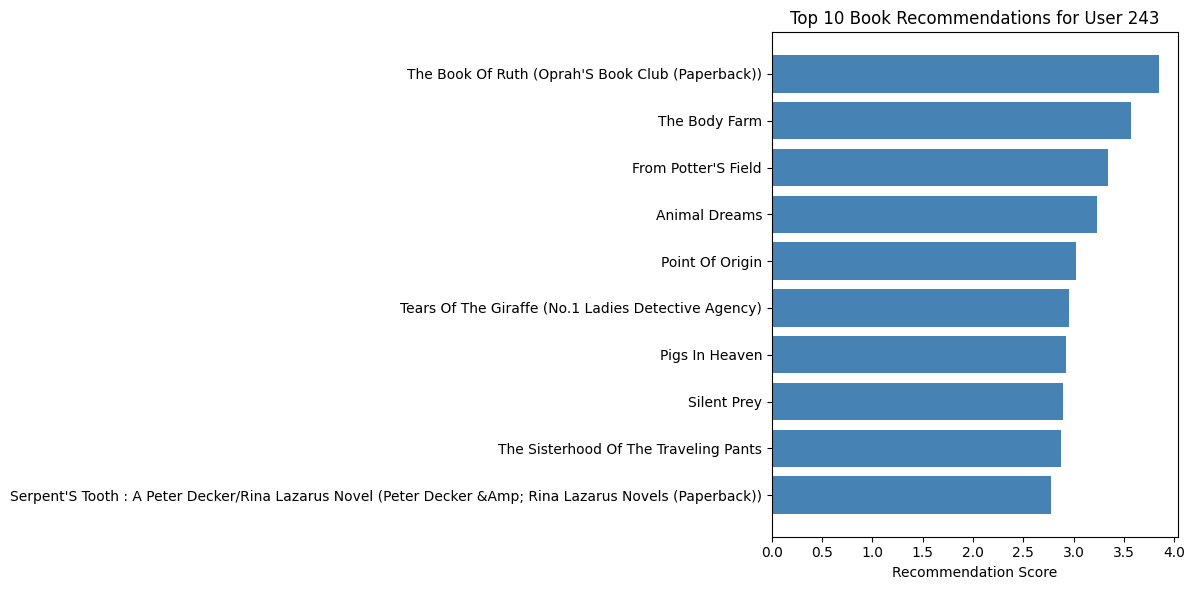

In [30]:
# Plot and save the top 10 recommendations for the first sample user.
uid = sample_users[0]
recs = demo_results[uid]

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    range(len(recs)),
    recs["Recommendation-Score"],
    color="steelblue"
)

ax.set_yticks(range(len(recs)))
ax.set_yticklabels(recs["Book-Title"])
ax.invert_yaxis()

ax.set_title(f"Top 10 Book Recommendations for User {uid}")
ax.set_xlabel("Recommendation Score")

fig.tight_layout()
fig.savefig("gold/recommendations_demo.png", bbox_inches="tight")
plt.show()


## Recommendation scoring

For each book rated at least 8, the system considers its 50 nearest
other books. Previously seen ISBNs are excluded, including books with
implicit zero ratings.

**Score(candidate) = Σ similarity(liked book, candidate) × rating**

The score determines ranking; it is not a predicted rating out of 10.

## Conclusion

The Book-Crossing dataset was processed using Medallion Architecture.
Bronze preserves raw data with ingestion timestamps. Silver cleans
the data and iteratively retains users and books with at least
10 explicit ratings.

Gold contains a sparse rating matrix, identifier mappings, book lookup,
user and book aggregates, and interaction history. Item-based
collaborative filtering uses cosine similarity to generate
personalized recommendations.

The system was demonstrated for three users. Sanity checks verify
distinct recommendations, exclusion of seen books and descending
scores. These checks verify functionality; recommendation accuracy
has not been evaluated on held-out data.

Limitations include cold-start users and books, reduced coverage
after frequency filtering, and separate treatment of different
ISBN editions of the same title.

In [32]:
# Create project documentation and package the generated data lake.
import json
import zipfile

readme = f"""# Book Recommendation System

## Objective
Build a book recommender using Medallion Architecture and
item-based collaborative filtering with cosine similarity.

## Dataset
Book-Crossing:
- BX-Books.csv
- BX-Users.csv
- BX-Book-Ratings.csv

## Architecture
- Bronze: Raw data stored as Parquet with ingestion timestamps.
- Silver: Cleaned explicit ratings and iterative frequency filtering.
- Gold: Sparse matrix, index mappings, lookup, aggregates and history.

## Results
- Users: {len(user_ids):,}
- Books: {len(book_ids):,}
- Explicit ratings: {rating_matrix.nnz:,}
- Gold matrix sparsity: {gold_sparsity:.2f}%

## Algorithm
Cosine similarity with scikit-learn NearestNeighbors.
Candidates are ranked by similarity-weighted liked-book ratings.
Previously seen ISBNs are excluded.

## Parameters
- Minimum ratings per user and book: 10
- Liked-book threshold: 8
- Candidate neighbors per liked book: 50
- Recommendations per user: 10

## How to Run
Upload the three original CSV files to /content in Google Colab.
Open LCS2023044_Book_Recommender.ipynb and run all cells in order.

## Validation
Demonstration users: 243, 805 and 1424.
Checks verify 10 unique recommendations, exclusion of seen ISBNs,
positive finite scores and descending ranking.
No held-out accuracy evaluation was performed.

## Limitations
Cold start, reduced coverage after filtering, and ISBN-level editions.
"""

Path("README.md").write_text(readme, encoding="utf-8")

Path("requirements.txt").write_text(
    "pandas\nnumpy\nmatplotlib\nscipy\nscikit-learn\npyarrow\n",
    encoding="utf-8"
)

config = {
    "min_ratings": 10,
    "liked_rating_threshold": 8,
    "candidate_neighbors": 50,
    "sample_users": sample_users,
    "matrix_shape": list(rating_matrix.shape),
    "observed_ratings": int(rating_matrix.nnz)
}

Path("gold/config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

export_files = [
    path
    for folder in ["bronze", "silver", "gold"]
    for path in sorted(Path(folder).rglob("*"))
    if path.is_file()
] + [Path("README.md"), Path("requirements.txt")]

display(pd.DataFrame([
    {
        "File": str(path),
        "Size (KB)": round(path.stat().st_size / 1024, 2)
    }
    for path in export_files
]))

with zipfile.ZipFile(
    "data_lake.zip",
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in export_files:
        archive.write(path, arcname=path.as_posix())

print("Created README.md, requirements.txt and data_lake.zip")

,File,Size (KB)
0,bronze/books.parquet,21160.82
1,bronze/ratings.parquet,9613.23
2,bronze/users.parquet,4382.34
3,silver/books.parquet,77.01
4,silver/ratings.parquet,106.99
5,silver/users.parquet,33.41
6,gold/book_aggregates.parquet,26.64
7,gold/book_ids.parquet,17.37
8,gold/book_lookup.parquet,66.03
9,gold/config.json,0.20


Created README.md, requirements.txt and data_lake.zip


In [33]:
# Download the generated data lake and project documentation.
from google.colab import files

files.download("data_lake.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>